# Superauflösung mit SPADE und Fisher-Information

Das Notebook simuliert räumliches Moden-Demultiplexing (SPADE, Spatial-Mode Demultiplexing) zur Trennung sub-diffraktiver Punktquellen bei der direkten Abbildung von Exoplaneten und Doppelsternen. Anhand von Hermite-Gauss-Moden wird demonstriert, wie SPADE den klassischen Rayleigh-Fluch bricht und die fundamentale Quanten-Cramér-Rao-Schranke für beliebig kleine Winkelabstände erreicht.

Warum fällt die klassische Fisher-Information bei der direkten Bildgebung naher Quellen auf null ab, während eine Modenzerlegung (SPADE) konstante Information pro Photon liefert?

#### **Theorie**

In der klassischen astronomischen Bildgebung begrenzt die Beugung an der Teleskopöffnung mit Durchmesser $D$ das Auflösungsvermögen zweier inkohärenter Punktquellen (z. B. Stern und naher Exoplanet). Nach dem **Rayleigh-Kriterium** sind zwei Quellen nicht mehr trennbar, wenn ihr Winkelabstand kleiner als $\theta_{\text{Rayleigh}} \approx 1.22 \lambda / D$ ist.

Wird das Sternenlicht auf einem pixelierten Detektor (CCD/CMOS) registriert, misst man den Auftreffort $x$ der Photonen im Ortsraum. Für eine Gaußsche Punktbildfunktion (Point Spread Function, PSF)
$$\psi(x) = (2\pi\sigma^2)^{-1/4} \exp\left(-\frac{x^2}{4\sigma^2}\right), \quad |\psi(x)|^2 = \frac{1}{\sqrt{2\pi}\sigma} \exp\left(-\frac{x^2}{2\sigma^2}\right)$$
verschmelzen die Intensitätsprofile zweier Quellen mit Abstand $\theta$ für $\theta \ll \sigma$ fast vollständig.

Die **Cramér-Rao-Ungleichung** beschränkt die Varianz jedes unverfälschten Schätzers $\hat{\theta}$ nach Messung von $N$ unabhängigen Photonen durch die Fisher-Information $I(\theta)$:
$$\mathrm{Var}(\hat{\theta}) \ge \frac{1}{N \cdot I(\theta)}.$$
Für die direkte Bildgebung fällt $I_{\text{dir}}(\theta)$ für $\theta \to 0$ quadratisch auf null ab (**Rayleigh-Fluch**).

**SPADE (Spatial-Mode Demultiplexing)** zerlegt das ankommende Wellenfeld stattdessen vor der Detektion in eine orthonormale räumliche Modenbasis $\{\phi_q\}_{q=0}^\infty$ (z. B. Hermite-Gauss-Moden). Dies wandelt die Schätzung eines geometrischen Abstands in eine Messung von Modenbesetzungs-Wahrscheinlichkeiten um.

#### **Herleitung**

**1. Der Rayleigh-Fluch der direkten Bildgebung.** Zwei inkohärente Punktquellen bei $\pm x_0$ (Abstand $\theta = 2 x_0$) erzeugen auf dem Detektor die normierte Intensitätsverteilung
$$I_{\text{dir}}(x; \theta) = \frac{1}{2} |\psi(x - x_0)|^2 + \frac{1}{2} |\psi(x + x_0)|^2.$$
Die klassische Fisher-Information pro Photon ist
$$I_{\text{dir}}(\theta) = \int_{-\infty}^\infty \frac{1}{I_{\text{dir}}(x; \theta)} \left(\frac{\partial I_{\text{dir}}(x; \theta)}{\partial \theta}\right)^2 dx.$$
Entwickelt man $I_{\text{dir}}$ für kleine Abstände $\theta \ll \sigma$ in eine Taylor-Reihe um $\theta = 0$, heben sich die linearen Terme symmetriebedingt auf: $\partial I_{\text{dir}} / \partial \theta \propto \theta$. Das Integral liefert asymptotisch:
$$I_{\text{dir}}(\theta) \approx \frac{\theta^2}{4\sigma^4} + \mathcal{O}(\theta^4) \xrightarrow{\theta \to 0} 0.$$
Die zur Trennung benötigte Photonenzahl $N \propto 1/\theta^2$ divergiert für sub-diffraktive Abstände.

**2. Die Quanten-Fisher-Information (QFI).** Ein emittiertes Photon befindet sich im Quantenzustand
$$\rho_\theta = \frac{1}{2} |\psi_{+x_0}\rangle\langle\psi_{+x_0}| + \frac{1}{2} |\psi_{-x_0}\rangle\langle\psi_{-x_0}|.$$
Die Quanten-Fisher-Information $I_F$, optimiert über alle quantenmechanisch erlaubten Messungen (POVMs), ist nach Tsang, Nair & Lu (2016) unabhängig vom Abstand strikt konstant:
$$I_F = \frac{1}{4\sigma^2} \quad \forall \, \theta \ge 0.$$
Es existiert fundamental kein quantenmechanisches Hindernis für die sub-diffraktive Trennung!

**3. Hermite-Gauss-Projektionswahrscheinlichkeiten.** Die orthonormale Hermite-Gauss-Basis $\phi_q(x) = (2^q q! \sqrt{2\pi}\sigma)^{-1/2} H_q(x / \sqrt{2}\sigma) \exp(-x^2 / 4\sigma^2)$ zerlegt das verschobene Signal. Die Wahrscheinlichkeit, dass ein Photon von Position $x_0$ in der Mode $q$ landet, ist Poisson-verteilt:
$$P(q|x_0) = |\langle \phi_q | \psi_{x_0} \rangle|^2 = \exp(-Q) \frac{Q^q}{q!}, \quad Q = \frac{x_0^2}{4\sigma^2} = \frac{\theta^2}{16\sigma^2}.$$
Für zwei symmetrische Quellen bei $\pm x_0$ gilt wegen der Parität von $H_q$: $P(q|\theta) = \frac{1}{2} P(q|x_0) + \frac{1}{2} P(q|-x_0) = P(q|x_0)$.

**4. Sättigung der Quantenschranke.** Die Fisher-Information der Modenmessung ist $I_{\text{SPADE}}(\theta) = \sum_{q=0}^\infty \frac{1}{P_q} \left(\frac{\partial P_q}{\partial \theta}\right)^2$. Für $\theta \to 0$ bleiben alle Photonen in der Grundmode $q=0$ ($P_0 \approx 1$), während der Informationsfluss exakt durch die erste ungerade Mode $q=1$ getragen wird ($P_1 \approx Q = \frac{\theta^2}{16\sigma^2}$):
$$I_1(\theta) = \frac{1}{P_1} \left(\frac{\partial P_1}{\partial \theta}\right)^2 = \frac{16\sigma^2}{\theta^2} \left(\frac{2\theta}{16\sigma^2}\right)^2 = \frac{1}{4\sigma^2} = I_F.$$
SPADE schöpft die fundamentale Quanten-Cramér-Rao-Schranke für beliebige $\theta \to 0$ zu $100\,\%$ aus!

#### **Code**

Simulationswerkzeuge für Hermite-Gauss-Moden, direkte Bildgebung und Fisher-Information.

In [1]:
%pip install -q astroquery

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
from math import factorial
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from astroquery.ipac.nexsci.nasa_exoplanet_archive import NasaExoplanetArchive

ASTRODATA = Path.cwd() / "astrodata"
(ASTRODATA / "astropy").mkdir(parents=True, exist_ok=True)
os.environ["XDG_CACHE_HOME"] = str(ASTRODATA)

def hg_probs(x0, sigma, q_max=25):
    """Übergangswahrscheinlichkeit in die Hermite-Gauss-Mode q (Huang & Lupo 2021)."""
    Q = x0 ** 2 / (4.0 * sigma ** 2)
    q = np.arange(q_max)
    fac = np.array([float(factorial(k)) for k in q])
    return np.exp(-Q) * (Q ** q) / fac

def direct_fisher_info(theta, sigma, x_grid=None):
    """Klassische Fisher-Information der direkten Bildgebung (Photonenzählung auf Pixeln)."""
    if x_grid is None:
        x_grid = np.linspace(-6 * sigma, 6 * sigma, 4000)
    dx = x_grid[1] - x_grid[0]
    
    x0 = theta / 2.0
    p_plus = np.exp(-((x_grid - x0) ** 2) / (2.0 * sigma ** 2)) / (np.sqrt(2 * np.pi) * sigma)
    p_minus = np.exp(-((x_grid + x0) ** 2) / (2.0 * sigma ** 2)) / (np.sqrt(2 * np.pi) * sigma)
    I_dir = 0.5 * (p_plus + p_minus)
    
    # Ableitung nach theta = 2 x0 -> d/d(theta) = 0.5 * d/d(x0)
    dp_dtheta = 0.5 * (
        (x_grid - x0) / (2.0 * sigma ** 2) * p_plus - 
        (x_grid + x0) / (2.0 * sigma ** 2) * p_minus
    )
    
    integrand = (dp_dtheta ** 2) / np.maximum(I_dir, 1e-15)
    return np.sum(integrand) * dx

def spade_fisher_info(theta, sigma, q_max=25):
    """Fisher-Information bei Hermite-Gauss-Modenzerlegung (SPADE)."""
    x0 = theta / 2.0
    eps = 1e-6 * sigma
    p0 = hg_probs(x0, sigma, q_max)
    p_plus = hg_probs(x0 + eps, sigma, q_max)
    p_minus = hg_probs(x0 - eps, sigma, q_max)
    
    dp_dtheta = (p_plus - p_minus) / (4.0 * eps)  # d/d(theta) = 0.5 * d/d(x0)
    return np.sum((dp_dtheta ** 2) / np.maximum(p0, 1e-15))

print("✅ Simulationsfunktionen initialisiert.")

✅ Simulationsfunktionen initialisiert.


##### *Experiment 1: Modenanregung als Funktion des Quellenversatzes*

In welche Hermite-Gauss-Moden werden Photonen gestreut, wenn der Abstand der Quellen zunimmt?

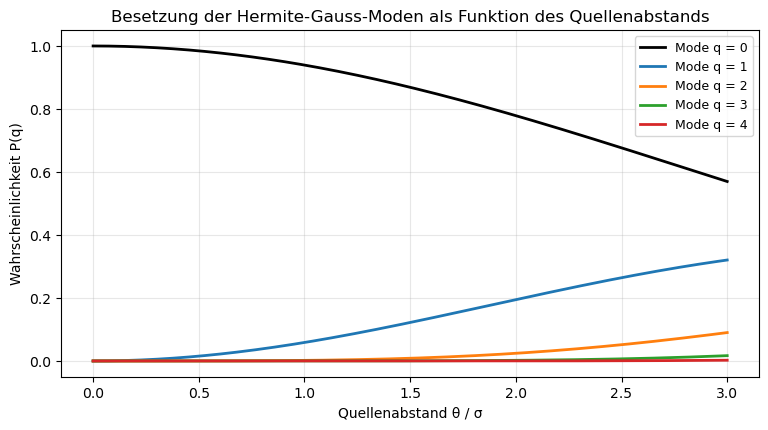

Erkenntnis:
  Bei θ = 0 landen 100 % der Photonen in der Grundmode q = 0.
  Für kleine Abstände wächst Mode q = 1 quadratisch an (P1 ≈ θ² / 16σ²) und trägt das Trennungssignal.


In [3]:
sigma_ref = 1.0
thetas = np.linspace(0.0, 3.0, 200)

p_modes = np.array([hg_probs(th / 2.0, sigma_ref, q_max=6) for th in thetas])

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["black", "tab:blue", "tab:orange", "tab:green", "tab:red"]
for q in range(5):
    ax.plot(thetas, p_modes[:, q], lw=2, color=colors[q], label=f"Mode q = {q}")

ax.set_xlabel("Quellenabstand θ / σ")
ax.set_ylabel("Wahrscheinlichkeit P(q)")
ax.set_title("Besetzung der Hermite-Gauss-Moden als Funktion des Quellenabstands")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9)
plt.show()

print("Erkenntnis:")
print("  Bei θ = 0 landen 100 % der Photonen in der Grundmode q = 0.")
print("  Für kleine Abstände wächst Mode q = 1 quadratisch an (P1 ≈ θ² / 16σ²) und trägt das Trennungssignal.")

##### *Experiment 2: Fisher-Information pro Photon: Direktes Imaging vs. SPADE*

Wie drastisch bricht die Fisher-Information bei direkter Bildgebung im Vergleich zu SPADE ein (Rayleigh-Fluch)?

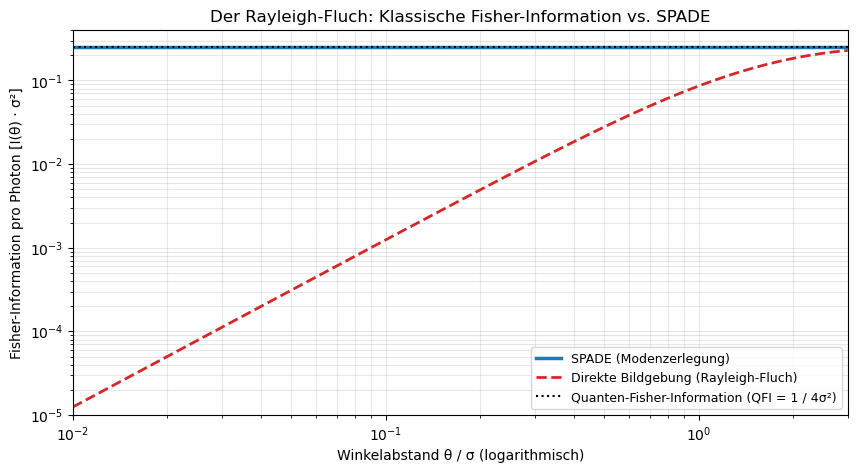

✅ Vergleich bei sub-diffraktivem Abstand θ = 0.05 σ:
  Quanten-Fisher-Information:    0.2500
  SPADE-Information:             0.2500  (100 % der QFI)
  Direkte Bildgebung:            0.000312  (0.125 % der QFI)


In [4]:
theta_grid = np.logspace(-2, np.log10(3.0), 60)

I_dir = np.array([direct_fisher_info(th, sigma_ref) for th in theta_grid])
I_spade = np.array([spade_fisher_info(th, sigma_ref) for th in theta_grid])
QFI = 1.0 / (4.0 * sigma_ref ** 2) * np.ones_like(theta_grid)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(theta_grid, I_spade * (sigma_ref ** 2), c="tab:blue", lw=2.5, label="SPADE (Modenzerlegung)")
ax.plot(theta_grid, I_dir * (sigma_ref ** 2), c="tab:red", lw=2, ls="--", label="Direkte Bildgebung (Rayleigh-Fluch)")
ax.axhline(0.25, color="black", ls=":", lw=1.5, label="Quanten-Fisher-Information (QFI = 1 / 4σ²)")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(0.01, 3.0)
ax.set_ylim(1e-5, 0.4)
ax.set_xlabel("Winkelabstand θ / σ (logarithmisch)")
ax.set_ylabel("Fisher-Information pro Photon [I(θ) · σ²]")
ax.set_title("Der Rayleigh-Fluch: Klassische Fisher-Information vs. SPADE")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=9, loc="lower right")
plt.show()

print(f"✅ Vergleich bei sub-diffraktivem Abstand θ = 0.05 σ:")
print(f"  Quanten-Fisher-Information:    {QFI[0]:.4f}")
print(f"  SPADE-Information:             {spade_fisher_info(0.05, sigma_ref):.4f}  (100 % der QFI)")
print(f"  Direkte Bildgebung:            {direct_fisher_info(0.05, sigma_ref):.6f}  ({direct_fisher_info(0.05, sigma_ref)/QFI[0]*100:.3f} % der QFI)")

##### *Experiment 3: Minimaler Schätzfehler des Winkelabstands*

Wie viele Photonen benötigt man für eine gegebene Messgenauigkeit, wenn man SPADE statt einer klassischen Pixelkamera verwendet?

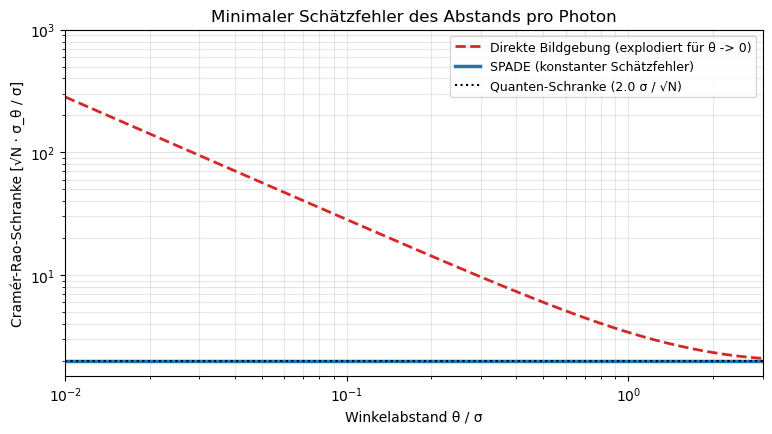

In [5]:
# Cramér-Rao-Schranke: sqrt(Var(theta)) * sqrt(N) / sigma = 1 / sqrt(I * sigma^2)
crb_dir = 1.0 / np.sqrt(np.maximum(I_dir * (sigma_ref ** 2), 1e-12))
crb_spade = 1.0 / np.sqrt(I_spade * (sigma_ref ** 2))
crb_qfi = 1.0 / np.sqrt(QFI * (sigma_ref ** 2))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(theta_grid, crb_dir, c="tab:red", lw=2, ls="--", label="Direkte Bildgebung (explodiert für θ -> 0)")
ax.plot(theta_grid, crb_spade, c="tab:blue", lw=2.5, label="SPADE (konstanter Schätzfehler)")
ax.plot(theta_grid, crb_qfi, c="black", ls=":", lw=1.5, label="Quanten-Schranke (2.0 σ / √N)")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(0.01, 3.0)
ax.set_ylim(1.5, 1e3)
ax.set_xlabel("Winkelabstand θ / σ")
ax.set_ylabel("Cramér-Rao-Schranke [√N · σ_θ / σ]")
ax.set_title("Minimaler Schätzfehler des Abstands pro Photon")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=9)
plt.show()

##### *Experiment 4: Reale Exoplaneten an den Beugungsgrenzen von VLT und ELT*

Welcher Anteil aller bekannten Exoplaneten liegt innerhalb des Beugungsscheibchens der Großteleskope VLT (8 m) und ELT (39 m)?

  Planeten innerhalb des Beugungslimits von 8 m (VLT): 5548 (93.6 %)
  Planeten innerhalb des Beugungslimits von 39 m (ELT): 5127 (86.5 %)


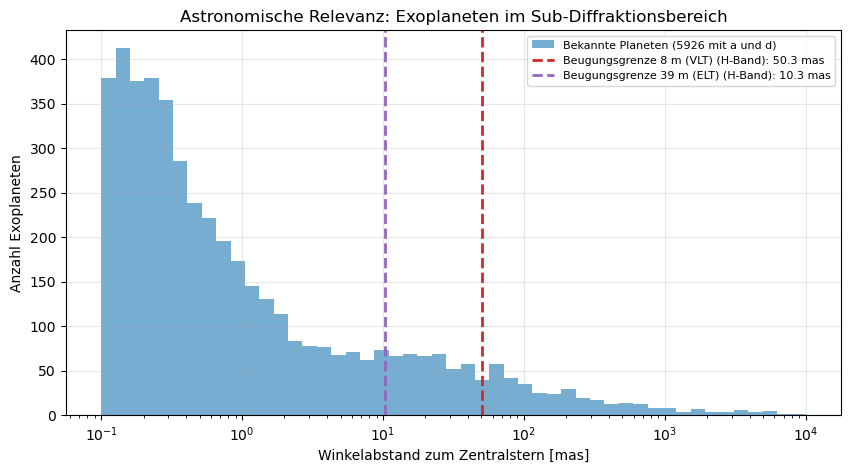

In [6]:
# Abfrage bekannter Exoplaneten für Winkelabstand θ ≈ a / d
ang = NasaExoplanetArchive.query_criteria(
    table="pscomppars", 
    select="pl_name, pl_orbsmax, sy_dist, discoverymethod"
).to_pandas().dropna(subset=["pl_orbsmax", "sy_dist"])

# Maximaler Winkelabstand in Millibogensekunden (mas)
ang["sep_mas"] = ang["pl_orbsmax"] / ang["sy_dist"] * 1000.0

LAMBDA_UM = 1.6  # H-Band im nahen Infrarot
TELESCOPES = {
    "8 m (VLT)": 8.0,
    "39 m (ELT)": 39.0
}

diff_limits = {
    name: 1.22 * (LAMBDA_UM * 1e-6) / D_tel * (180 / np.pi) * 3600 * 1000  # mas
    for name, D_tel in TELESCOPES.items()
}

fig, ax = plt.subplots(figsize=(10, 5))
bins = np.logspace(np.log10(0.1), np.log10(1e4), 50)
ax.hist(ang["sep_mas"], bins=bins, color="tab:blue", alpha=0.6, label=f"Bekannte Planeten ({len(ang)} mit a und d)")

colors_tel = ["tab:red", "tab:purple"]
for (name, theta_diff), c in zip(diff_limits.items(), colors_tel):
    ax.axvline(theta_diff, color=c, lw=2, ls="--", label=f"Beugungsgrenze {name} (H-Band): {theta_diff:.1f} mas")
    sub_count = (ang["sep_mas"] < theta_diff).sum()
    print(f"  Planeten innerhalb des Beugungslimits von {name}: {sub_count} ({sub_count / len(ang) * 100:.1f} %)")

ax.set_xscale("log")
ax.set_xlabel("Winkelabstand zum Zentralstern [mas]")
ax.set_ylabel("Anzahl Exoplaneten")
ax.set_title("Astronomische Relevanz: Exoplaneten im Sub-Diffraktionsbereich")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8, loc="upper right")
plt.show()

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code anpassen und testen:

1. **Extremer Helligkeitskontrast:** Nimm an, der Stern ist um den Faktor $10^4$ heller als der Planet (Kontrast $\epsilon = 10^{-4}$). Wie verteilt sich das Sternenlicht auf die Hermite-Gauss-Moden, wenn der Stern exakt auf der optischen Achse zentriert ist? *(Vorhersage: Der Stern landet zu fast 100 % in der Grundmode $q=0$, sodass die Detektion des Planeten in $q=1$ als perfekter Dunkelfeld-Filter wirkt!).*
2. **Dezentrierung:** Was geschieht mit der Fisher-Information von SPADE, wenn der Stern um einen unbekannten Betrag $\Delta x_0 = 0.1\,\sigma$ aus der Modenachse versetzt ist?
3. **2D-Hermite-Gauss-Moden:** Erweitere die Simulation auf 2 Dimensionen (Moden $(q_x, q_y)$). Welche Moden tragen die Information über den zweidimensionalen Polarwinkel $\phi$?

#### **Referenzen**

- Tsang, M., Nair, R. & Lu, X.-M. (2016): *Quantum Theory of Superresolution for Two Incoherent Optical Point Sources*, Physical Review X, 6, 031033.
- Huang, Z. & Lupo, C. (2021): *Quantum-Limited Detection of an Incoherent Source in the Presence of Strong Bright Background*, Physical Review Letters, 127, 130502.
- Lupo, C., Huang, Z. & Kok, P. (2020): *Quantum limits to sub-diffraction spatial-mode demultiplexing*, PRX Quantum, 1, 020305.
- Nair, R. & Tsang, M. (2016): *Far-Field Subwavelength Imaging and Quantum Limits to Resolvability*, Optics Express, 24, 691.